In [1]:
import sys
import os
sys.path.append(os.path.abspath("") + "/..")

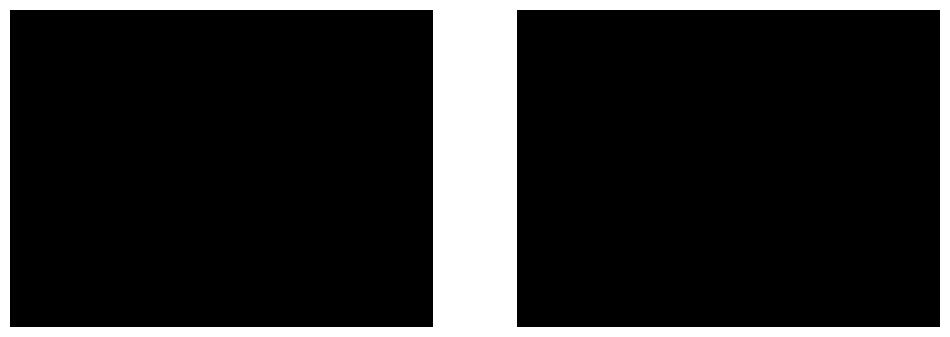

Failed to capture frames


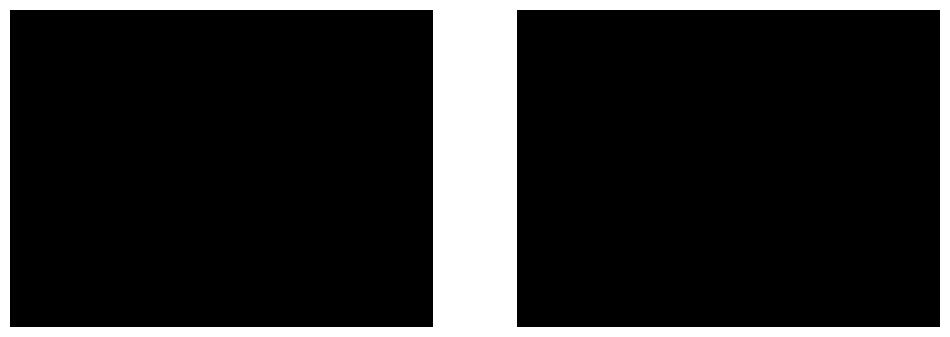

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

from camera import get_imx219_gstreamer_pipeline

# Open both cameras using gstreamer pipelines
width = 640
height = 480
framerate = 30

pipeline_0 = get_imx219_gstreamer_pipeline(0, width, height, framerate)
pipeline_1 = get_imx219_gstreamer_pipeline(1, width, height, framerate)

cap_0 = cv2.VideoCapture(pipeline_0, cv2.CAP_GSTREAMER)
cap_1 = cv2.VideoCapture(pipeline_1, cv2.CAP_GSTREAMER)

# Create figure with two subplots side by side
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5))

# Initialize images with dummy frames
im0 = ax0.imshow(np.zeros((height, width, 3), dtype=np.uint8))
im1 = ax1.imshow(np.zeros((height, width, 3), dtype=np.uint8))
ax0.axis("off")
ax1.axis("off")

# Display the figure in Jupyter
display(fig)

while True:
    # Read frames from both cameras
    ret0, frame0 = cap_0.read()
    ret1, frame1 = cap_1.read()
    
    if not ret0 or not ret1:
        print("Failed to capture frames")
        break

    # Convert BGR to RGB for both frames
    frame0 = cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB)
    frame1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB)

    # Update both images
    im0.set_data(frame0)
    im1.set_data(frame1)
    
    # Clear and redisplay the figure
    clear_output(wait=True)
    display(fig)

    # Small delay to prevent excessive CPU usage
    time.sleep(0.01)

In [2]:
# Release the webcam
cap_0.release()
cap_1.release()

In [7]:
cap_0.read()

(False, None)

In [8]:
pipeline_0

'libcamerasrc camera-index=0 ! video/x-raw, format=(string)YUY2, width=(int)640, height=(int)480, framerate=(fraction)30/1 ! videoconvert ! video/x-raw, format=(string)BGR ! appsink'